# Variable Importance and Feature Selection

This notebook demonstrates two related uses of BART for understanding predictor relevance:

- **Variable importance** ranks predictors according to how they are used by the posterior tree ensemble.
- **Feature selection** compares observed importance against a permutation-null distribution to produce an explicit selected feature set.

GenBART provides both standard split-count variable inclusion proportions and a log marginal-likelihood-weighted importance measure. The permutation-based selector can be applied to either importance definition.

We use synthetic data with a known set of relevant predictors so that the resulting rankings and selected sets can be inspected directly.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from genbart import RegBart, BartVariableSelector

In [2]:
rng = np.random.default_rng(0)

n = 300
p = 20

X = rng.uniform(0.0, 1.0, size=(n, p))

y = (
    4.0 * np.sin(np.pi * X[:, 0] * X[:, 1])
    + 3.0 * (X[:, 2] - 0.5) ** 2
    + rng.normal(0.0, 0.2, size=n)
)

feature_names = [f"x{i}" for i in range(p)]
true_features = {"x0", "x1", "x2"}

Only `x0`, `x1`, and `x2` affect the response. Predictors `x0` and `x1`
enter through a nonlinear interaction, while `x2` contributes through a
nonlinear main effect. The remaining 17 predictors are independent noise
variables.

The larger number of irrelevant predictors makes the example useful for
illustrating the distinction between ranking variables by importance and
selecting variables relative to a permutation-null distribution.

In [3]:
model = RegBart(
    m=20,
    n_burn=200,
    n_samples=500,
    random_state=0,
)

model.fit(X, y)

In [4]:
raw_importance = model.variable_inclusion(kind="raw")
logml_importance = model.variable_inclusion(kind="logml")

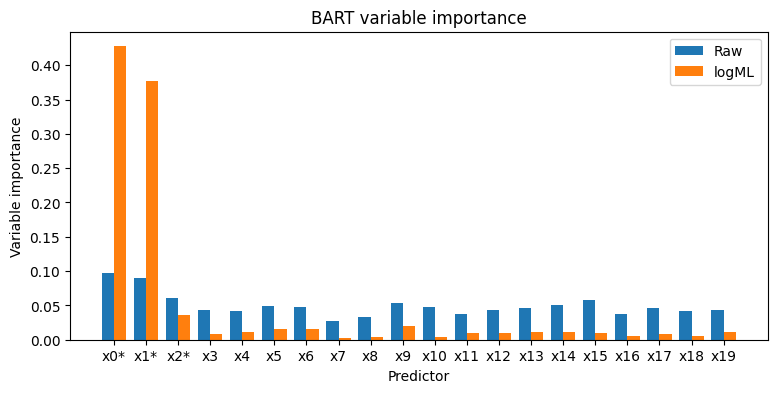

In [5]:
x_pos = np.arange(p)
width = 0.38

fig, ax = plt.subplots(figsize=(9, 4))

ax.bar(
    x_pos - width / 2,
    raw_importance,
    width,
    label="Raw",
)

ax.bar(
    x_pos + width / 2,
    logml_importance,
    width,
    label="logML",
)

labels = [
    f"{name}*" if name in true_features else name
    for name in feature_names
]

ax.set_xticks(x_pos)
ax.set_xticklabels(labels)
ax.set_ylabel("Variable importance")
ax.set_xlabel("Predictor")
ax.set_title("BART variable importance")
ax.legend()

plt.show()

An asterisk marks predictors that are truly relevant in the data-generating process.

These importance values come from a single fitted BART model. They provide relative importance information, but by themselves they do not define a selected feature set.

In [6]:
selector = BartVariableSelector.from_model(
    model,
    n_permutations=20,
    n_repeats=5,
    alpha=0.05,
    method="global_se",
    importance_kind="raw",
    random_state=0,
    verbose=False,
)

`BartVariableSelector` repeatedly refits fresh BART models on both the observed response and permuted responses.

Here, each observed or permuted importance estimate is averaged across three BART fits. Twenty response permutations are used to construct the null importance distribution.

The selector computes both raw and logML importance during the same fitting procedure, so the two results can be compared without running the permutation experiment twice.

In [7]:
raw_result = selector.fit(
    X,
    y,
    feature_names=feature_names,
)

logml_result = selector.get_result("logml")

In [8]:
print("True features:")
print(sorted(true_features))

print("\nRaw importance selection:")
print(raw_result.selected_features())

print("\nlogML importance selection:")
print(logml_result.selected_features())

True features:
['x0', 'x1', 'x2']

Raw importance selection:
['x0', 'x1']

logML importance selection:
['x0', 'x1']


In [9]:
raw_result.compare_methods()

[{'method': 'local', 'n_selected': 3, 'selected_features': ['x0', 'x1', 'x2']},
 {'method': 'global_max', 'n_selected': 2, 'selected_features': ['x0', 'x1']},
 {'method': 'global_se', 'n_selected': 2, 'selected_features': ['x0', 'x1']}]

In [10]:
logml_result.compare_methods()

[{'method': 'local', 'n_selected': 2, 'selected_features': ['x0', 'x1']},
 {'method': 'global_max', 'n_selected': 2, 'selected_features': ['x0', 'x1']},
 {'method': 'global_se', 'n_selected': 2, 'selected_features': ['x0', 'x1']}]

The thresholding methods operate on the same observed and permutation-null importance estimates; only the rule used to construct the selection threshold changes.

The default `global_se` rule is used below. A predictor is selected only when its observed importance is strictly greater than its threshold.

In [11]:
def plot_selection_result(result, title):
    x_pos = np.arange(len(result.feature_names))
    thresholds = result.thresholds("global_se")
    selected = result.selected_mask("global_se")

    fig, ax = plt.subplots(figsize=(9, 4))

    bars = ax.bar(x_pos, result.importance)

    for bar, is_selected in zip(bars, selected):
        bar.set_alpha(1.0 if is_selected else 0.35)

    ax.scatter(
        x_pos,
        thresholds,
        marker="_",
        s=350,
        linewidths=2,
        label="global-SE threshold",
    )

    labels = [
        f"{name}*" if name in true_features else name
        for name in result.feature_names
    ]

    ax.set_xticks(x_pos)
    ax.set_xticklabels(labels)
    ax.set_xlabel("Predictor")
    ax.set_ylabel("Mean observed importance")
    ax.set_title(title)
    ax.legend()

    plt.show()

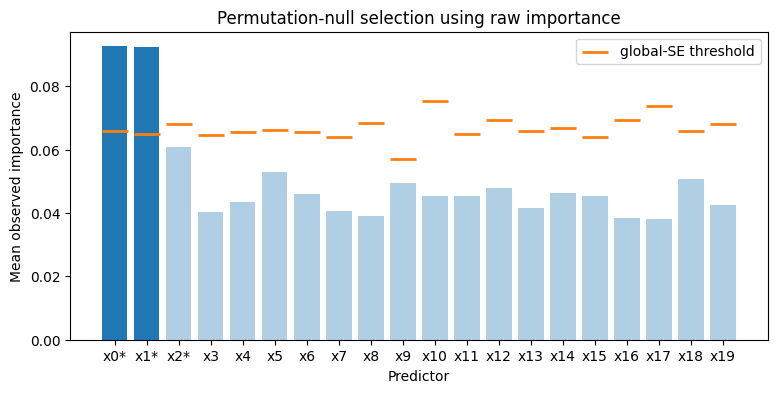

In [12]:
plot_selection_result(
    raw_result,
    "Permutation-null selection using raw importance",
)

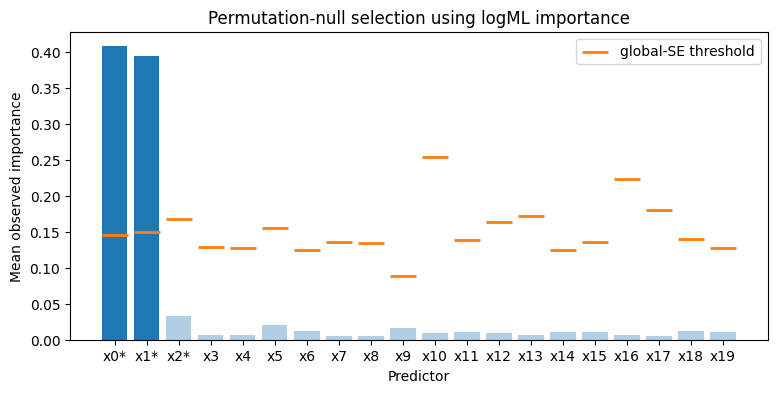

In [13]:
plot_selection_result(
    logml_result,
    "Permutation-null selection using logML importance",
)

## Interpretation

Variable importance and variable selection answer different questions.

The raw and logML measures provide relative summaries of how predictors contribute to the fitted BART ensembles. The permutation-null procedure adds a reference distribution obtained by destroying the predictor-response relationship and uses that distribution to decide which predictors exceed a chosen null threshold.

Because the true relevant predictors are known in this synthetic example, the selected sets can be compared directly with `x0`, `x1`, and `x2`.

This example is illustrative rather than a benchmark: selection behavior depends on the data-generating process, BART configuration, number of repeated fits, number of permutations, and thresholding rule.